In [218]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,SampleID,canvas_size,is_oil_painting,brush_type,num_colors,colorfulness,complexity,brightness,contrast,stroke_density,...,dominant_warm_colors,dominant_color,art_period_hint,auction_house,image_quality,brightness_log,complexity_x_stroke,fake_style_score,painter_style_score,target_price
0,332,60x50,True,medium,71,0.616240,0.755582,0.647338,0.587923,0.702118,...,False,red,baroque,Online,low,0.499161,0.530508,0.349718,0.536437,50800
1,410,80x90,True,medium,60,0.660715,0.474923,0.538822,0.599076,0.528112,...,False,yellow,modern,Online,low,0.431017,0.250813,0.258722,0.163906,37400
2,77,80x50,True,fine,64,0.684877,0.380591,0.608029,0.500152,0.508521,...,False,mixed,baroque,Sothebys,low,0.475009,0.193539,0.797662,0.137732,35500
3,869,80x50,True,medium,56,0.427938,0.581636,0.562086,0.483896,0.550152,...,False,blue,modern,Local,low,0.446022,0.319988,0.569981,0.394542,43200
4,139,80x130,True,fine,55,0.481406,0.629780,0.476093,0.493429,0.681710,...,False,red,modern,Local,medium,0.389398,0.429328,0.723147,0.321858,54500


In [219]:
#subtasks

def calculate_score(row):
    score = 0
    if row.stroke_density > 0.7:
        score += 2
    if row.complexity > 0.65:
        score += 2
    if row.uses_gold_leaf == True:
        score += 1
    if row.has_signature == True:
        score += 1
    if row.num_colors > 65 and row.colorfulness > 0.7:
        score += 2
    if row.contrast < 0.4 or row.brightness < 0.45 or row.brightness > 0.75:
        score -= 1
    if score >= 5:
        return "Autentic"
    else:
        return "Incert"

subtask1 = df_test.apply(calculate_score, axis=1)

df_1 = pd.DataFrame({
    "SampleID": df_test.SampleID,
    "subtaskID": "Task1",
    "Answer": subtask1
})

df_1.head()

,SampleID,subtaskID,Answer
0,1179,Task1,Incert
1,866,Task1,Autentic
2,102,Task1,Incert
3,440,Task1,Incert
4,59,Task1,Incert


In [207]:
df_train.columns

Index(['SampleID', 'canvas_size', 'is_oil_painting', 'brush_type',
       'num_colors', 'colorfulness', 'complexity', 'brightness', 'contrast',
       'stroke_density', 'has_signature', 'is_framed', 'uses_gold_leaf',
       'is_restored', 'dominant_warm_colors', 'dominant_color',
       'art_period_hint', 'auction_house', 'image_quality', 'brightness_log',
       'complexity_x_stroke', 'fake_style_score', 'painter_style_score',
       'target_price'],
      dtype='object')

In [220]:
#preprocessing

df_train['canvas_length'] = df_train.canvas_size.map(lambda x : int(str(x).split('x')[0]))
df_train['canvas_height'] = df_train.canvas_size.map(lambda x : int(str(x).split('x')[1]))
df_train = df_train.drop(columns='canvas_size')

df_test['canvas_length'] = df_test.canvas_size.map(lambda x : int(str(x).split('x')[0]))
df_test['canvas_height'] = df_test.canvas_size.map(lambda x : int(str(x).split('x')[1]))
df_test = df_test.drop(columns='canvas_size')

df_train.brush_type = df_train.brush_type.map({'fine': 0, "medium": 1, 'mixed': 2, 'thick': 3})
df_train.image_quality = df_train.image_quality.map({'low': 0, "medium": 1, 'high': 2})

df_test.brush_type = df_test.brush_type.map({'fine': 0, "medium": 1, 'mixed': 2, 'thick': 3})
df_test.image_quality = df_test.image_quality.map({'low': 0, "medium": 1, 'high': 2})

from sklearn.preprocessing import LabelEncoder

to_encode = ['dominant_color', 'art_period_hint', 'auction_house']

df_train_encoded = pd.get_dummies(df_train, columns=to_encode)

df_test_encoded = pd.get_dummies(df_test, columns=to_encode)
df_test_encoded = df_test_encoded.reindex(columns=df_train_encoded.columns, fill_value=0)

df_train.head()

,SampleID,is_oil_painting,brush_type,num_colors,colorfulness,complexity,brightness,contrast,stroke_density,has_signature,...,art_period_hint,auction_house,image_quality,brightness_log,complexity_x_stroke,fake_style_score,painter_style_score,target_price,canvas_length,canvas_height
0,332,True,1,71,0.616240,0.755582,0.647338,0.587923,0.702118,True,...,baroque,Online,0,0.499161,0.530508,0.349718,0.536437,50800,60,50
1,410,True,1,60,0.660715,0.474923,0.538822,0.599076,0.528112,True,...,modern,Online,0,0.431017,0.250813,0.258722,0.163906,37400,80,90
2,77,True,0,64,0.684877,0.380591,0.608029,0.500152,0.508521,True,...,baroque,Sothebys,0,0.475009,0.193539,0.797662,0.137732,35500,80,50
3,869,True,1,56,0.427938,0.581636,0.562086,0.483896,0.550152,True,...,modern,Local,0,0.446022,0.319988,0.569981,0.394542,43200,80,50
4,139,True,0,55,0.481406,0.629780,0.476093,0.493429,0.681710,True,...,modern,Local,1,0.389398,0.429328,0.723147,0.321858,54500,80,130


In [209]:
features = [col for col in df_train.columns if (col != 'SampleID' and col != 'target_price')]
target = 'target_price'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=features)
X_final = pd.DataFrame(scaler.transform(X_final), columns=features)

X.head()

,is_oil_painting,brush_type,num_colors,colorfulness,complexity,brightness,contrast,stroke_density,has_signature,is_framed,...,dominant_color,art_period_hint,auction_house,image_quality,brightness_log,complexity_x_stroke,fake_style_score,painter_style_score,canvas_length,canvas_height
0,0.5581,-0.357407,0.888341,-0.229192,1.100724,0.653643,0.330957,0.167840,0.66767,0.825385,...,0.748885,-1.382685,0.499821,-1.214957,0.671409,0.667975,-0.616170,-0.056315,-0.718444,-1.440051
1,0.5581,-0.357407,-0.485543,0.159612,-1.006939,-0.818619,0.475947,-1.166152,0.66767,-1.211555,...,1.452338,0.186319,0.499821,-1.214957,-0.817218,-1.149931,-0.983523,-1.359997,-0.006673,-0.011163
2,0.5581,-1.265107,0.014051,0.370835,-1.715347,0.120323,-0.810013,-1.316345,0.66767,-1.211555,...,0.045431,-1.382685,1.419033,-1.214957,0.143804,-1.522191,1.192183,-1.451595,-0.006673,-1.440051
3,0.5581,-0.357407,-0.985137,-1.875357,-0.205558,-0.502990,-1.021339,-0.997183,0.66767,-1.211555,...,-1.361475,0.186319,-0.419390,-1.214957,-0.489428,-0.700317,0.273034,-0.552880,-0.006673,-1.440051
4,0.5581,-1.265107,-1.110036,-1.407927,0.155994,-1.669672,-0.897408,0.011381,0.66767,0.825385,...,0.748885,0.186319,-0.419390,0.001267,-1.726388,0.010344,0.891368,-0.807242,-0.006673,1.417725


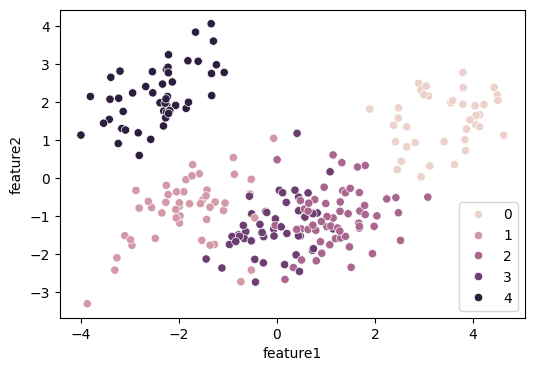

In [210]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=43)
labels = kmeans.fit_predict(X_final)

pca = PCA(n_components=2)
X_redus = pd.DataFrame(pca.fit_transform(X_final), columns=['feature1', 'feature2'])

plt.figure(figsize=(6, 4))
sns.scatterplot(x=X_redus.feature1, y=X_redus.feature2, hue=labels)
plt.show()

In [211]:
df_2 = pd.DataFrame({
    "SampleID": df_test.SampleID,
    "subtaskID": "Task2",
    "Answer": labels
})

df_2.head()

,SampleID,subtaskID,Answer
0,1179,Task2,4
1,866,Task2,0
2,102,Task2,4
3,440,Task2,4
4,59,Task2,1


In [213]:
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score

model = CatBoostRegressor(random_state=42, verbose=0)

cross_val_score(model, X, y, cv=3, scoring='neg_mean_absolute_error').mean()

-1045.588105528558

In [214]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [215]:
df_final = pd.DataFrame({
    "SampleID": df_test.SampleID,
    "subtaskID": "Task3",
    "Answer": y_preds
})

df_final.head()

,SampleID,subtaskID,Answer
0,1179,Task3,39013.177873
1,866,Task3,74808.159232
2,102,Task3,33645.574015
3,440,Task3,38421.486751
4,59,Task3,46711.112644


In [216]:
submission = pd.concat([df_1, df_2, df_final])

submission

,SampleID,subtaskID,Answer
0,1179,Task1,Incert
1,866,Task1,Autentic
2,102,Task1,Incert
3,440,Task1,Incert
4,59,Task1,Incert
...,...,...,...
235,383,Task3,50514.148081
236,868,Task3,58753.480769
237,543,Task3,43998.256857
238,1194,Task3,38672.686933


In [217]:
submission.to_csv("submission.csv", index=False)